# 15 Dog Detection

In [1]:
import matplotlib.patches as patches
import matplotlib.pyplot as plt

from woofdata.path import data_path, load_data_dir_from_env_file
from woofdecoder.config import load_config
from woofdecoder.preprocess.bark_detector import load_bark_detector, settings_from_config
from woofdecoder.preprocess.bark_segments import build_segments
from woofdecoder.preprocess.dog_detector import add_dog_boxes, load_dog_detector

## Loading necessary project files

In [2]:
load_data_dir_from_env_file()
VIDEO_PATH = data_path("test/media_test.mp4")

### Settings from pipeline.yaml

In [3]:
config = load_config()
settings = settings_from_config(config)
print(f"{settings}")

DetectionSettings(threshold=0.08, median_frames=1, max_gap_s=0.0, min_event_s=0.16)


## Loading Bark Detector and Building Segments

In [4]:
print("Loading the bark detector")
bark_detector = load_bark_detector(config["bark_detector"]["model"], verbose=True)
dog_detector = load_dog_detector(config["dog_detector"]["model"], config["dog_detector"]["score_threshold"])

print("Building segments")
segments = build_segments(VIDEO_PATH, bark_detector, settings)

Loading the bark detector
dilation_list_t_dim: 
[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
MN(
  (features): Sequential(
    (0): ConvNormActivation(
      (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(16, eps=0.001, momentum=0.01, affine=True, bias=True, track_running_stats=True)
      (2): Hardswish()
    )
    (1): InvertedResidual(
      (block): Sequential(
        (0): ConvNormActivation(
          (0): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=16, bias=False)
          (1): BatchNorm2d(16, eps=0.001, momentum=0.01, affine=True, bias=True, track_running_stats=True)
          (2): ReLU(inplace=True)
        )
        (1): ConvNormActivation(
          (0): Conv2d(16, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (1): BatchNorm2d(16, eps=0.001, momentum=0.01, affine=True, bias=True, track_running_stats=True)
        )
      )
    )
    (2): InvertedResidual(
      (block): Se

c:\Users\kimy8\Desktop\Deep Learning\dog-vocal-interpreter\.venv\Lib\site-packages\torchvision\ops\misc.py:121: UserWarning: Don't use ConvNormActivation directly, please use Conv2dNormActivation and Conv3dNormActivation instead.
  warnings.warn(
c:\Users\kimy8\Desktop\Deep Learning\dog-vocal-interpreter\.venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
c:\Users\kimy8\Desktop\Deep Learning\dog-vocal-interpreter\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\Users\kimy8\Desktop\Deep Learning\dog-vocal-interpreter\.venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Loading RF-DETR nano (keeping only 'dog')
[2026-10-31 22:37:19] [INFO] rf-detr - File C:\Users\kimy8\.roboflow\models\rf-detr-nano.pth already exists with correct MD5 hash.


[2026-10-31 22:37:19] [WARNING] rf-detr - Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-10-31 22:37:19] [WARNING] rf-detr - Using patch size 16 instead of 14, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.


[2026-10-31 22:37:19] [INFO] rf-detr - File C:\Users\kimy8\.roboflow\models\rf-detr-nano.pth already exists with correct MD5 hash.
Building segments
Building bark segments for media_test.mp4
Audio: 5.46 s
Scored 137 frames of 40 ms
Found 1 dog sounds (threshold 0.08)


C:\Users\kimy8\Desktop\Deep Learning\dog-vocal-interpreter\third_party\PretrainedSED\models\frame_passt\preprocess.py:129: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=False):


Segment 1/1:
  0.00  -  5.44s
dog vocalizing 0.70, 10 frames
growl         0.00  -  0.76s 0.50
bark          0.76  -  1.00s 0.62
growl         1.00  -  3.80s 0.81
bark          3.80  -  4.08s 0.61
growl         4.08  -  4.64s 0.69
bark          4.64  -  4.96s 0.62
growl         4.96  -  5.44s 0.60


## Dog Detection

In [5]:
print("Finding the dog in each segment's frames")
segments = [add_dog_boxes(segment, dog_detector) for segment in segments]
print(f"Dog visible in {sum(s.dog_visible for s in segments)}/{len(segments)} segments")

c:\Users\kimy8\Desktop\Deep Learning\dog-vocal-interpreter\.venv\Lib\site-packages\supervision\annotators\core.py:12: UserWarning: OpenCV (`opencv-python`) is not installed; supervision is using its pure NumPy fallback backend instead. Some operations may be slower or behave slightly differently. Install `opencv-python` for full performance and compatibility.
  from supervision import _cv2 as cv2
[2026-10-31 22:37:23] [WARNING] rf-detr - Model is not optimized for inference. Latency may be higher than expected. For full GPU throughput (e.g. ~8x on T4 via FP16 Tensor Cores), call model.inference(dtype=torch.float16).


Finding the dog in each segment's frames
  0.00 s: dogs per frame [1, 1, 1, 1, 1, 1, 1, 1, 1, 1] -> dog in 10/10 frames
Dog visible in 1/1 segments


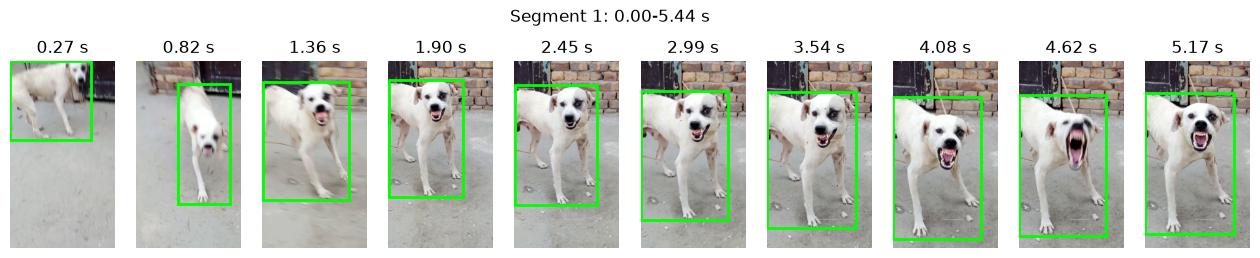

In [6]:
for number, segment in enumerate(segments, start=1):
    figure, axes = plt.subplots(1, len(segment.frames), figsize=(16, 3))
    figure.suptitle(f"Segment {number}: {segment.start_s:.2f}-{segment.end_s:.2f} s")
    for axis, frame, time_s, box in zip(axes, segment.frames, segment.frame_times_s, segment.dog_boxes):
        axis.imshow(frame)
        axis.set_title(f"{time_s:.2f} s" if box is not None else f"{time_s:.2f} s, no dog")
        if box is not None:
            x, y, w, h = box
            axis.add_patch(patches.Rectangle((x, y), w, h, fill=False, edgecolor="lime", linewidth=2))
        axis.axis("off")
    plt.show()

## Full Bark Segment

In [7]:
for number, segment in enumerate(segments, start=1):
    print(f"Segment {number}")
    segment.print_segment()

Segment 1
BarkSegment  [media_test]
----------------------------------------
  time        0.00 - 5.44 s  (5.44 s)
  confidence  0.70
  audio       87040 samples @ 16000 Hz
  video       10 frames, 1080x1920, 0.27 - 5.17 s
  dog boxes   dog in 10/10 frames
  sound sections (7):
    growl         0.00 -   0.76 s  (0.76 s)  score 0.50
    bark          0.76 -   1.00 s  (0.24 s)  score 0.62
    growl         1.00 -   3.80 s  (2.80 s)  score 0.81
    bark          3.80 -   4.08 s  (0.28 s)  score 0.61
    growl         4.08 -   4.64 s  (0.56 s)  score 0.69
    bark          4.64 -   4.96 s  (0.32 s)  score 0.62
    growl         4.96 -   5.44 s  (0.48 s)  score 0.60
